## ISOM4030 Lab 4 - Model Generalization

There is an open-source, commercially usable machine learning toolkit called [scikit-learn](https://scikit-learn.org/stable/index.html). This toolkit contains implementations of many of the algorithms you may use for a machine learning project.


In [156]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import SGDRegressor, LogisticRegression, LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline


%matplotlib inline

%config InlineBackend.figure_format="retina"


In [157]:
# simulate a dataset with a true pattern described by y=sin(2πx)
np.random.seed(42)
x_eval = np.linspace(0, 1, 500)
y_eval = np.random.normal(loc=np.sin(2 * x_eval * np.pi), scale=0.25)
# generate random values from a normal (Gaussian) distribution, mean based on sine wave, sd = 0.25

reordered_index = np.random.choice(np.arange(500), size=500, replace=False)

x = x_eval[reordered_index]
y = y_eval[reordered_index]

# sample 15 examples into the training and validation sets, respectively
x_train = x[:15]
y_train = y[:15]
x_valid = x[-30:-15]
y_valid = y[-30:-15]

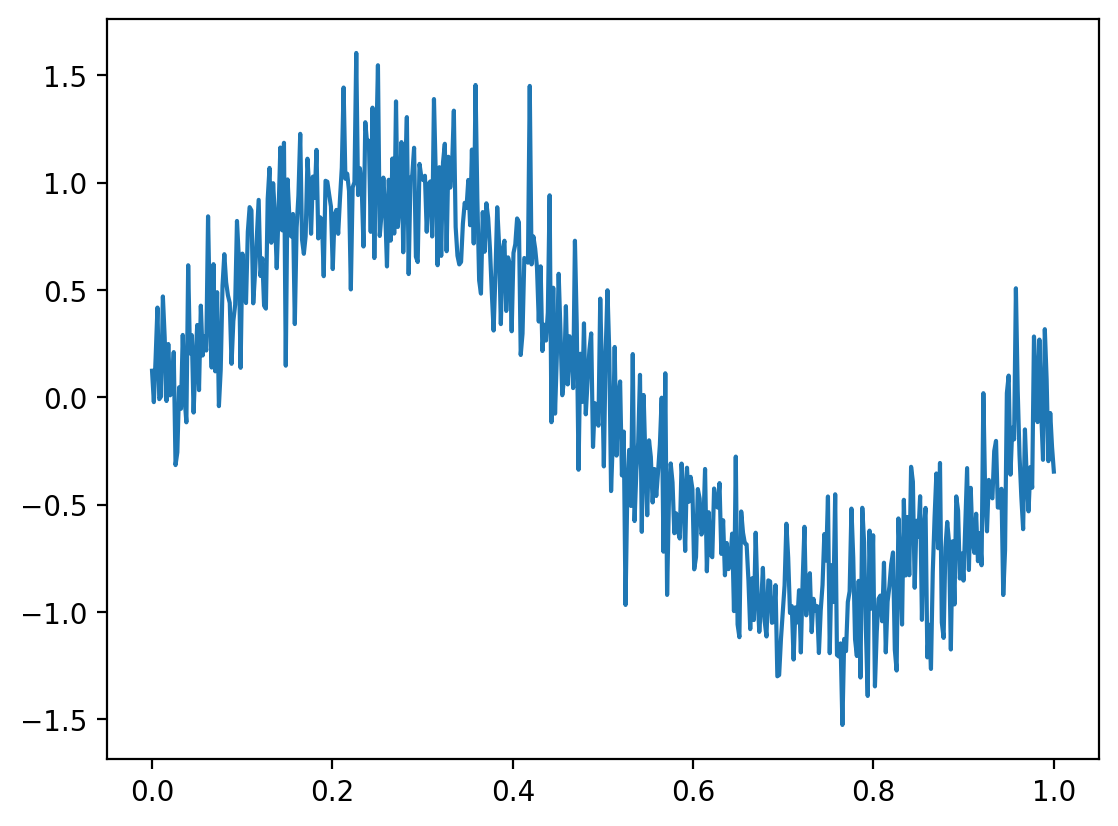

In [158]:
plt.plot(x_eval, y_eval)

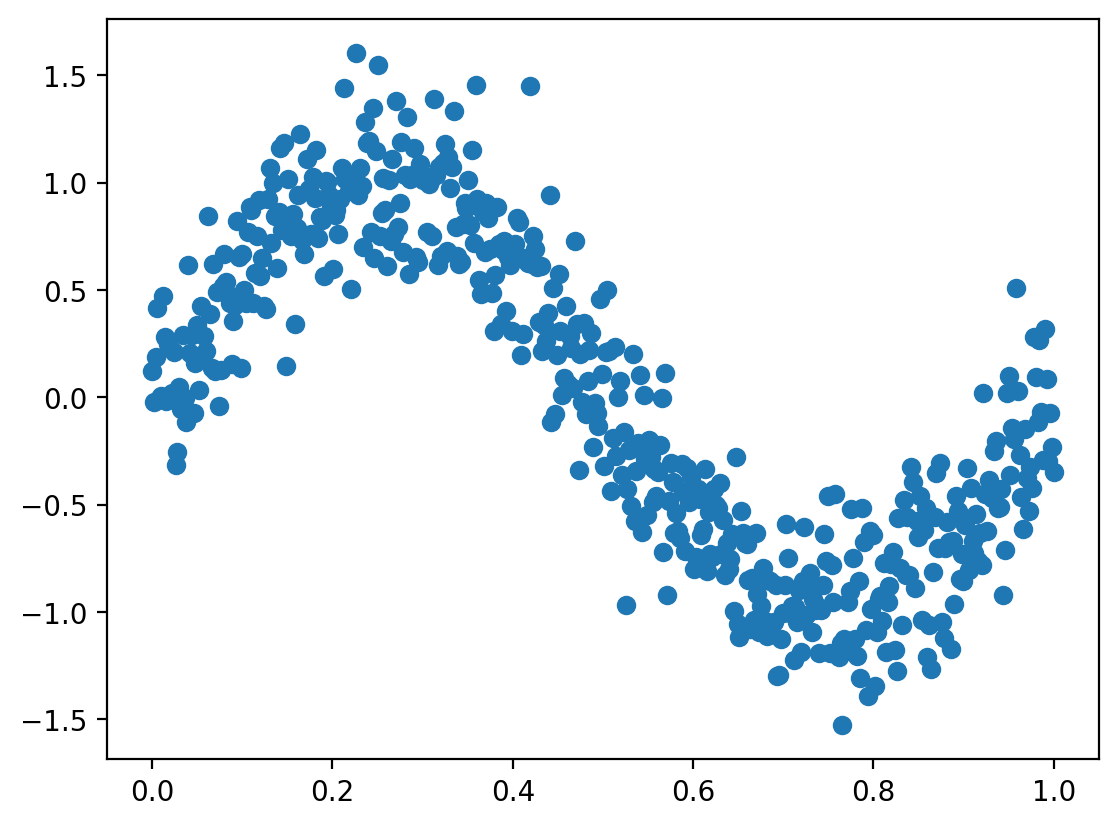

In [159]:
plt.scatter(x, y)

In [160]:
x_train, y_train

(array([0.09819639, 0.56713427, 0.98997996, 0.7254509 , 0.03006012,
        0.45290581, 0.49498998, 0.3246493 , 0.43286573, 0.53507014,
        0.61322645, 0.82164329, 0.16432866, 0.08416834, 0.85170341]),
 array([ 0.13781956, -0.71887278,  0.31786483, -1.01531761,  0.04718047,
         0.30767231, -0.13185862,  1.18165363,  0.2162126 , -0.57610866,
        -0.33349587, -0.72247898,  1.22806066,  0.47562461, -0.46052193]))

In [161]:
# define a utility function for plotting model fit

def plot_model_fit(ax, x, y, model=None, valid_data=None):
    x_eval = np.linspace(0, 1, 500)
    ax.scatter(x, y, marker='x', color='r', s=50, zorder=1)
    ax.plot(x_eval, np.sin(2*x_eval*np.pi), lw=1, color='k', zorder=3, ls="dashed", alpha=0.5)
    ax.set(ylim=[-1.6, 1.6])
    if model:
        model.fit(x, y)
        ax.plot(x_eval, model.predict(x_eval.reshape(-1, 1)), lw=2, color='#0096ff')  # predict() -- Predict using the linear model.
        train_mse = ((model.predict(x_train) - y_train)**2).mean()/2                  # Mean square error
        ax.text(0.17, -1.23, f'Training MSE: {train_mse:.3f}',  c='k', fontsize=11)

    if valid_data:
        x_valid, y_valid = valid_data
        ax.scatter(x_valid, y_valid, marker='x', color=(52/255, 168/255, 83/255), s=50, zorder=1)
        valid_mse = ((model.predict(x_valid) - y_valid)**2).mean()/2
        ax.text(0.17, -1.43, f'Validation MSE: {valid_mse:.2f}', c='k', fontsize=11)


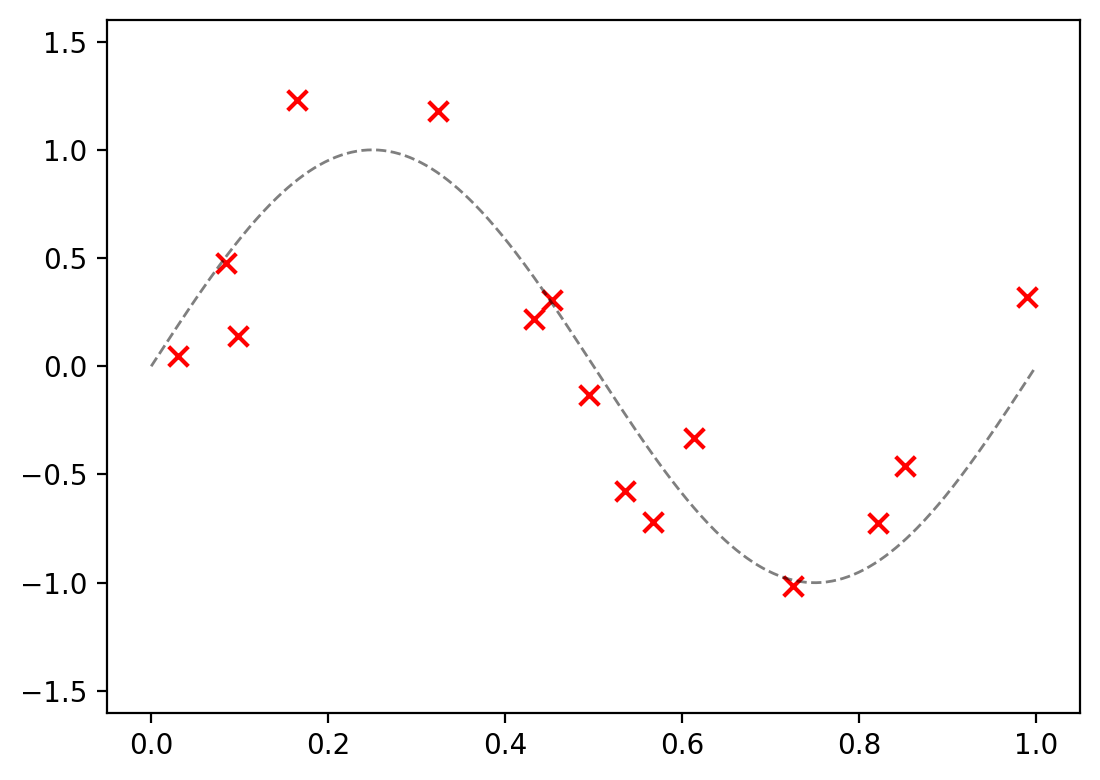

In [162]:
# plot the true function and the simulated training data

fig, ax = plt.subplots(1, 1, figsize=(5.6, 4))
plot_model_fit(ax, x_train, y_train)
plt.tight_layout()


 ## Create and fit the regression model



[`sklearn.linear_model.LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) is Scikit-learn's linear regression implementation, which is based on the normal equation method.

In [163]:
lr_model = LinearRegression()

# fitting the model is as simple as calling the model's fit method
# the input fearues should be presented as a 2d array of shape (n_samples, n_features)
x_train = x_train.reshape(-1, 1)
lr_model.fit(x_train, y_train)

# after model fitting
# the intercept term and the coefficient terms are accessed via 2 different model attributes
print(f"model parameters:  b:{lr_model.intercept_},  w: {lr_model.coef_}")

model parameters:  b:0.5777312809447126,  w: [-1.21236892]


### Make predictions
Predict the targets of the training data. Use both the `predict` routine and compute using $w$ and $b$.

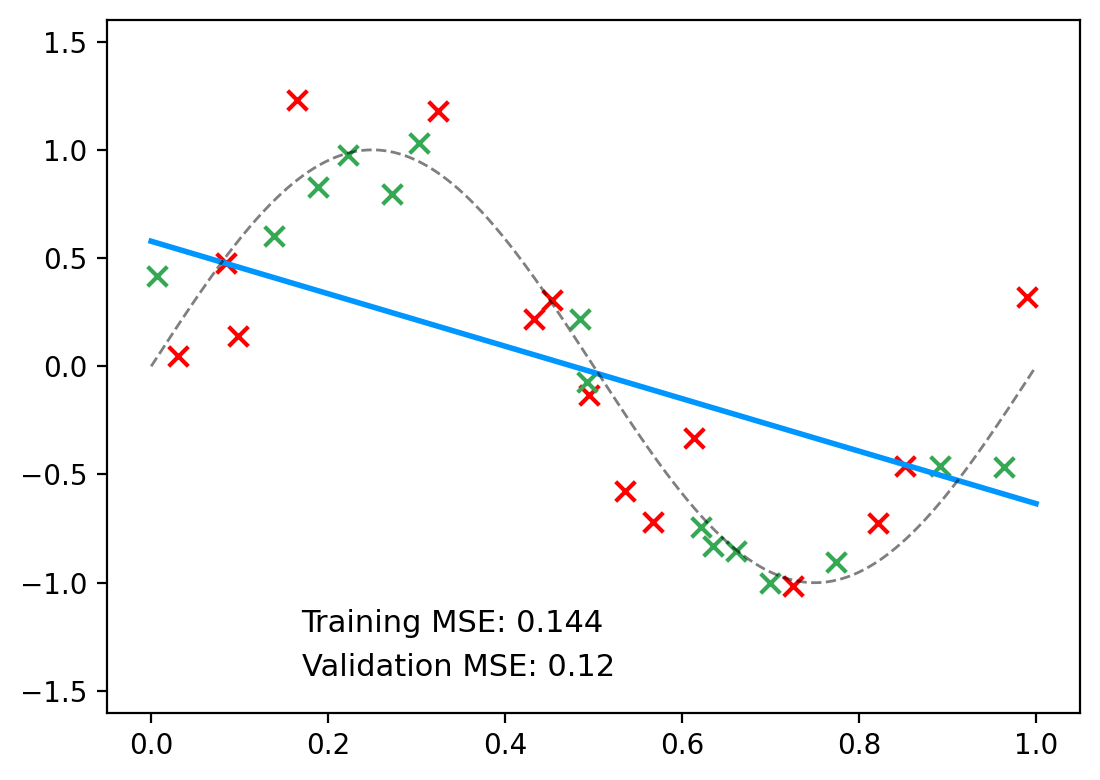

In [164]:
fig, ax = plt.subplots(1, 1, figsize=(5.6, 4))
plot_model_fit(ax, x_train, y_train, lr_model, (x_valid.reshape(-1,1), y_valid))
plt.tight_layout()

 ## Create models for polynomial regression

To create a polynomial regression model, we can use [`sklearn.preprocessing.PolynomialFeatures`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html) to generate needed polynomial and interaction features.

In [165]:
poly = PolynomialFeatures(degree=3, include_bias=False)
x_poly_train = poly.fit_transform(x_train.reshape(-1, 1))
# now the input features include x, x squared, and x cubed.
x_poly_train.shape

(15, 3)

In [166]:
# poly.fit_transform([[2],[3]])

In [167]:
x_poly_train

array([[9.81963928e-02, 9.64253156e-03, 9.46861816e-04],
       [5.67134269e-01, 3.21641279e-01, 1.82413791e-01],
       [9.89979960e-01, 9.80060321e-01, 9.70240077e-01],
       [7.25450902e-01, 5.26279011e-01, 3.81789583e-01],
       [3.00601202e-02, 9.03610829e-04, 2.71626502e-05],
       [4.52905812e-01, 2.05123674e-01, 9.29017041e-02],
       [4.94989980e-01, 2.45015080e-01, 1.21280010e-01],
       [3.24649299e-01, 1.05397167e-01, 3.42171164e-02],
       [4.32865731e-01, 1.87372741e-01, 8.11072388e-02],
       [5.35070140e-01, 2.86300055e-01, 1.53190611e-01],
       [6.13226453e-01, 3.76046683e-01, 2.30601773e-01],
       [8.21643287e-01, 6.75097690e-01, 5.54689485e-01],
       [1.64328657e-01, 2.70039076e-02, 4.43751588e-03],
       [8.41683367e-02, 7.08430890e-03, 5.96274496e-04],
       [8.51703407e-01, 7.25398693e-01, 6.17824538e-01]])

In [168]:
y_train

array([ 0.13781956, -0.71887278,  0.31786483, -1.01531761,  0.04718047,
        0.30767231, -0.13185862,  1.18165363,  0.2162126 , -0.57610866,
       -0.33349587, -0.72247898,  1.22806066,  0.47562461, -0.46052193])

In [169]:
lr_model.fit(x_poly_train, y_train)
lr_model.predict(x_poly_train)

array([ 0.57503653, -0.39604368,  0.50674901, -0.94380754, -0.0316424 ,
        0.21956467, -0.01039837,  0.80434132,  0.32598691, -0.2287499 ,
       -0.61386437, -0.86679668,  0.88871446,  0.47524713, -0.75090284])

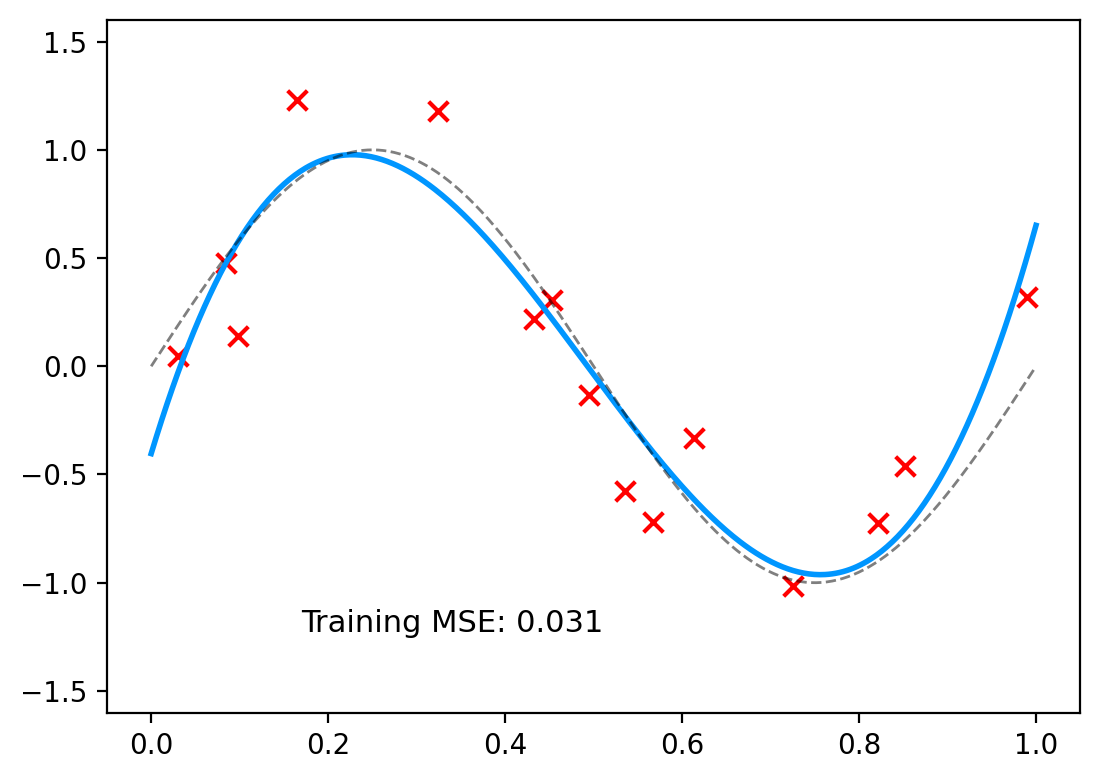

In [170]:
fig, ax = plt.subplots(1, 1, figsize=(5.6, 4))

ax.scatter(x_train, y_train, marker='x', c='r', s=50, zorder=1)
ax.plot(x_eval, np.sin(2*x_eval*np.pi), lw=1, color='k', zorder=3, ls="dashed", alpha=0.5)

# to plot the fitting curve, we have to generate the same set of polynomial terms for x_eval
ax.plot(x_eval, lr_model.predict(poly.fit_transform(x_eval.reshape(-1, 1))), lw=2, color='#0096ff')

mse = ((lr_model.predict(x_poly_train) - y_train)**2).mean()/2
ax.text(0.17, -1.23, f'Training MSE: {mse:.3f}',  c='k', fontsize=11)
ax.set(ylim=[-1.6, 1.6])
plt.tight_layout()


## Create a machine learning pipeline

[`sklearn.pipeline.Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) allows us to create a machine learing pipeline by chaining the final model with a list of preceding transformations, and fit the entire pipeline in one shot:


In [171]:
# use the Pipeline constructor to wrap a sequence of label-object pairs
pipeline = Pipeline([('polynomial', PolynomialFeatures(degree=3, include_bias=False)),
                     ('regression', LinearRegression())])
pipeline

Pipeline(steps=[('polynomial',
                 PolynomialFeatures(degree=3, include_bias=False)),
                ('regression', LinearRegression())])

In [172]:
# use the Pipeline constructor to wrap a sequence of label-object pairs
pipeline.fit(x_train, y_train)
pipeline.predict(x_train)

array([ 0.57503653, -0.39604368,  0.50674901, -0.94380754, -0.0316424 ,
        0.21956467, -0.01039837,  0.80434132,  0.32598691, -0.2287499 ,
       -0.61386437, -0.86679668,  0.88871446,  0.47524713, -0.75090284])

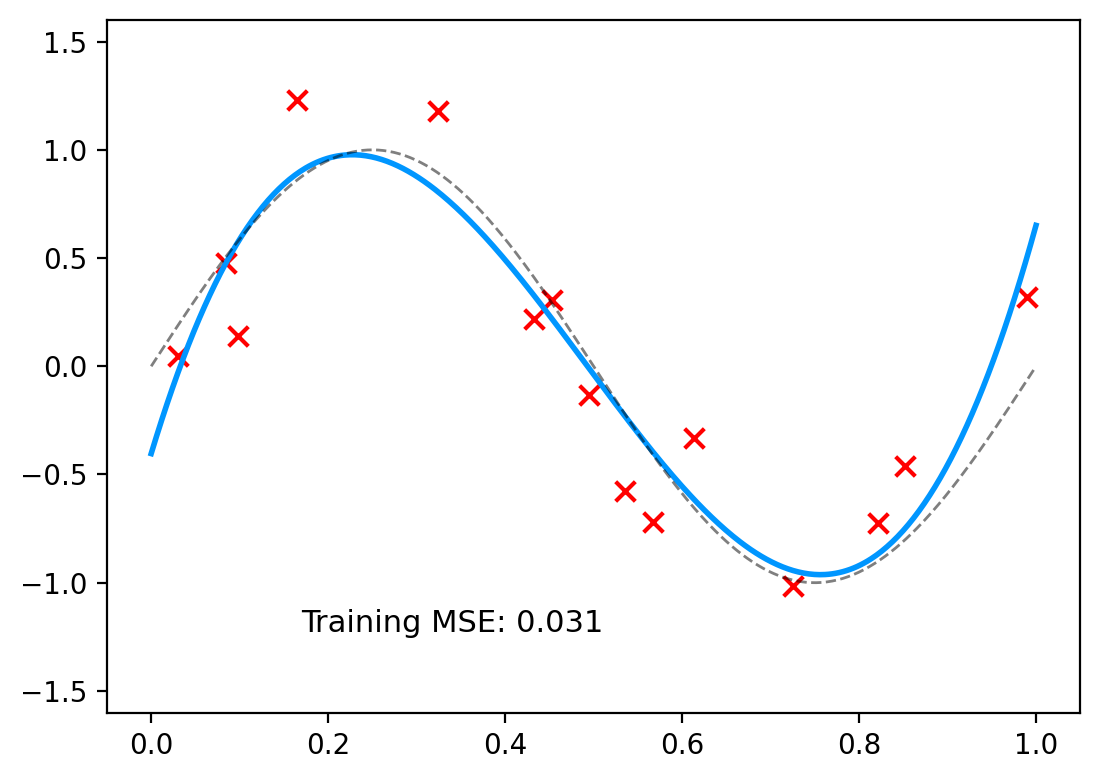

In [173]:
fig, ax = plt.subplots(1, 1, figsize=(5.6, 4))
plot_model_fit(ax, x_train, y_train, pipeline)
plt.tight_layout()

Different parts of a Pipleline can be accessed with dictionary-style indexing:

In [189]:
# A list of tuple can be converted to a dictionary
# tuple_a = [('a', 1), ('b', 2), ('c', 3)]
# dict(tuple_a)

In [174]:
pipeline['polynomial']

PolynomialFeatures(degree=3, include_bias=False)

In [175]:
pipeline['regression']

LinearRegression()

In [176]:
pipeline['regression'].intercept_,  pipeline['regression'].coef_

(np.float64(-0.4034741301109876),
 array([ 13.50786853, -38.65392128,  26.2006065 ]))

We are allowed to reset parameters or provide new parameters for different parts of a `Pipeline` using [`.set_params()`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html#sklearn.pipeline.Pipeline.set_params):


In [177]:
# the keyword used to indicate a target parameter is composed by
# combing the part label and the name of the target parameter with __ (double underscores)
pipeline.set_params(polynomial__degree=10)
pipeline

Pipeline(steps=[('polynomial',
                 PolynomialFeatures(degree=10, include_bias=False)),
                ('regression', LinearRegression())])

In [178]:
pipeline['polynomial']

PolynomialFeatures(degree=10, include_bias=False)

**<font color='steelblue' > Question 1</font>**:

Complete the following code to generate the plot as follows:


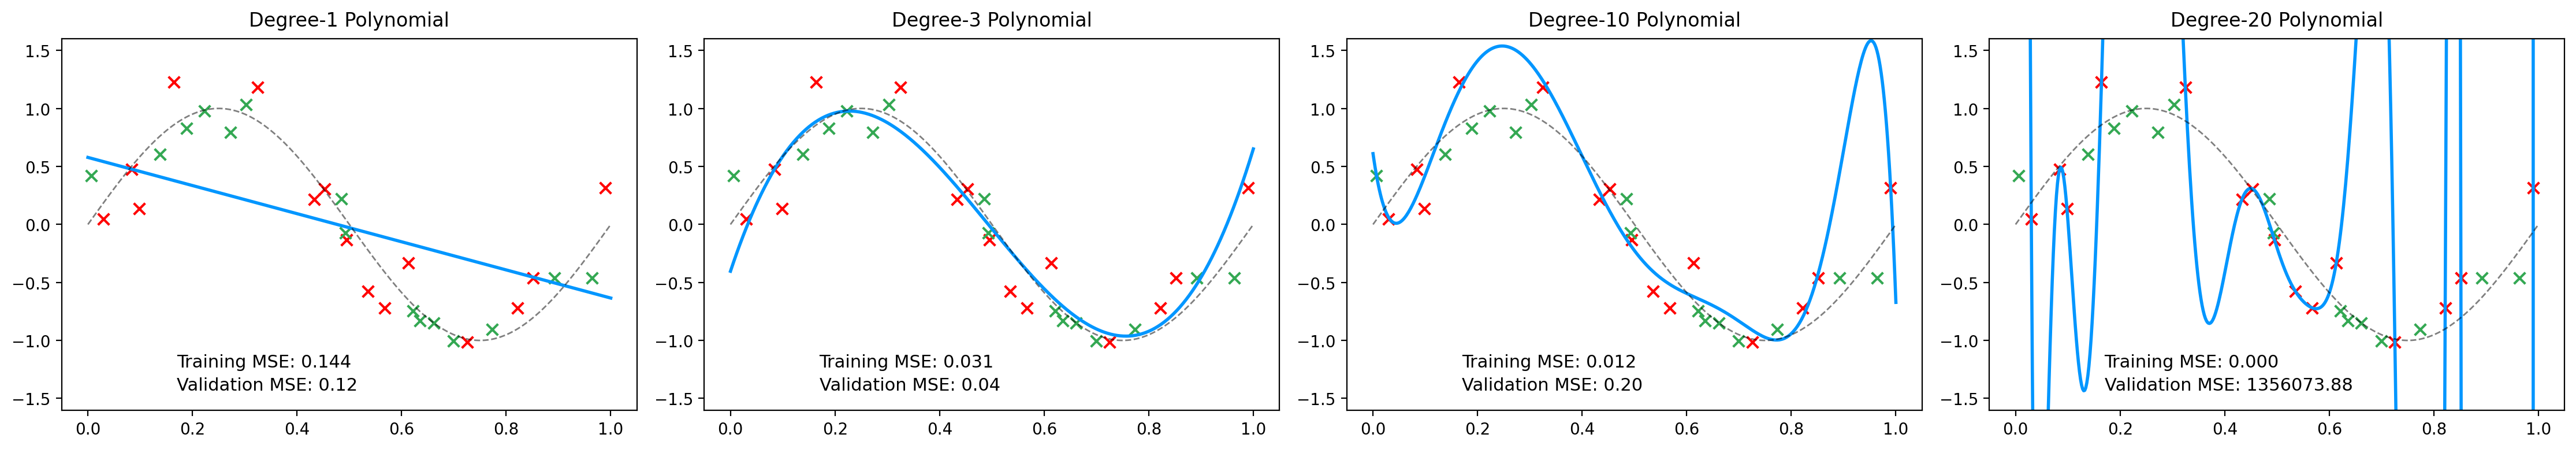

In [179]:
fig, axes = plt.subplots(1, 4, figsize=(22.4, 4))



# start your code here

pipeline_d = Pipeline([('polynomial', PolynomialFeatures(include_bias=False)),
                       ('regression', LinearRegression())])
for d, ax in zip([1, 3, 10, 20], axes.flat):

    pipeline_d.set_params(polynomial__degree=d).fit(x_train, y_train)
    plot_model_fit(ax, x_train, y_train, pipeline_d, (x_valid.reshape(-1,1), y_valid))
    ax.set_title(f"Degree-{d} Polynomial", fontsize=12, pad=8)

# end your code here

plt.tight_layout()
plt.show()

## Polynomial regression with L2 regularization



A regression model that uses L2 regularization is called ridge regression, and implemented by [`sklearn.linear_model.Ridge`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).

In [180]:
pipeline_ridge = Pipeline([('polynomial', PolynomialFeatures(degree=10, include_bias=False)),
                           ('ridge', Ridge())])

The regularization parameter $\lambda$ is set via the `alpha` parameter of the `Ridge` constructor:

In [181]:
pipeline_ridge.set_params(ridge__alpha=1e-3)    # E-notation -- 1e-3 = 1 x 10**(-3)

Pipeline(steps=[('polynomial',
                 PolynomialFeatures(degree=10, include_bias=False)),
                ('ridge', Ridge(alpha=0.001))])

**<font color='steelblue' > Question 2</font>**:

Complete the following code to generate the plot as follows:

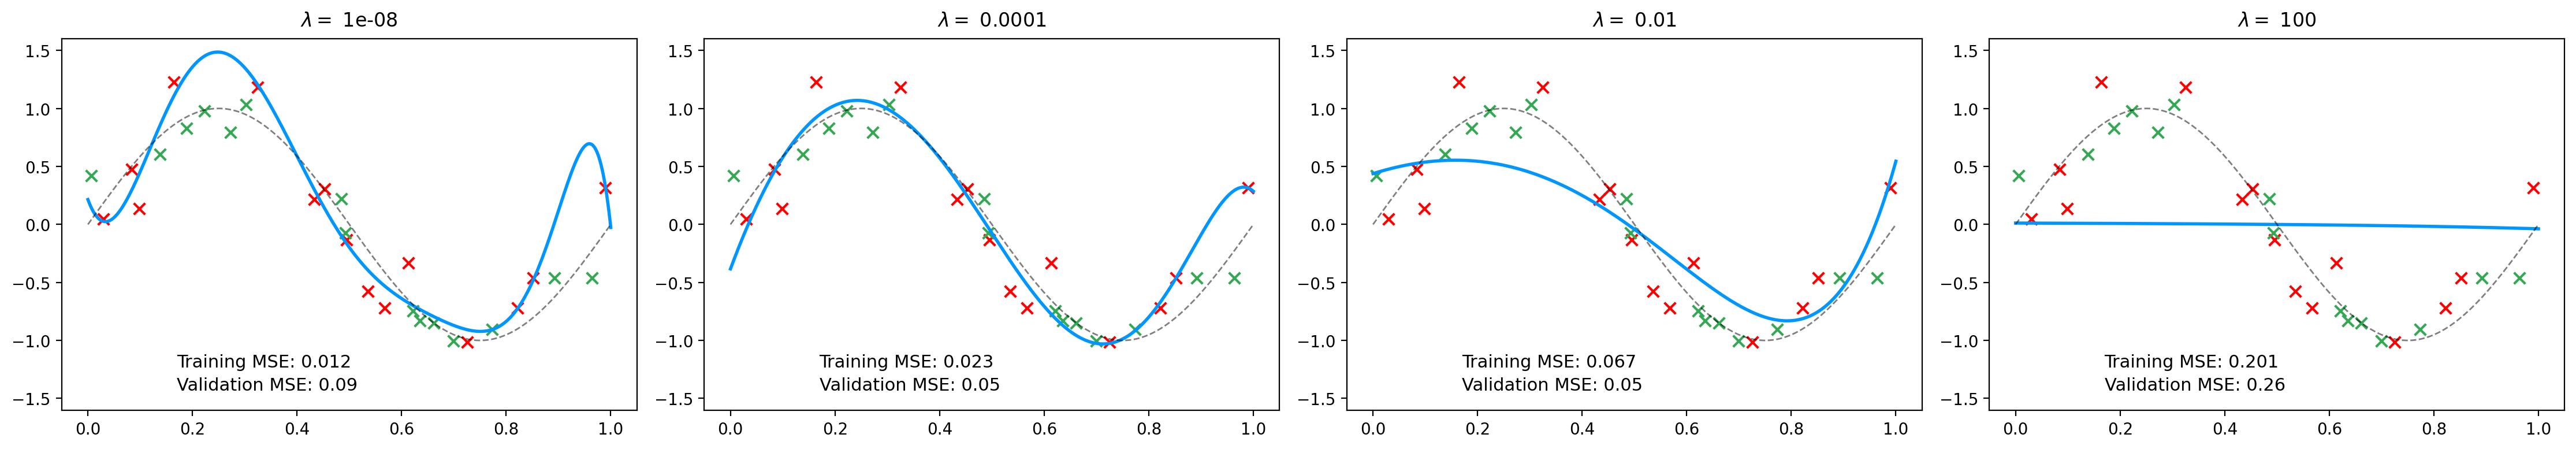

In [182]:
fig, axes = plt.subplots(1, 4, figsize=(22.4, 4))

# start your code here

for reg_param, ax in zip([1e-8, 1e-4, 1e-2, 100], axes.flat):

    pipeline_ridge.set_params(ridge__alpha=reg_param).fit(x_train, y_train)
    plot_model_fit(ax, x_train, y_train, pipeline_ridge, (x_valid.reshape(-1,1), y_valid))
    ax.set_title(r'$\lambda = $'+ f" {reg_param}", fontsize=12, pad=8)

# end your code here

plt.tight_layout()
plt.show()

## Fit a logistic regression model

We can build a logistic regression model by calling the `fit` method of [sklearn.linear_model.LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

Download the *new_circle_data.csv* file from Canvas and upload it onto the virtual machine that hosts this programming session on Google Colab.

In [183]:
data = np.loadtxt("new_circle_data.csv", delimiter = ',')
x_train = data[:-1,:].T  # The 1st 2 rows in the csv represent 2 sets of independant variables
y_train = data[-1,:]    # The 3sd row in the csv represents the target variable

pipeline_logistic = Pipeline([('polynomial', PolynomialFeatures(include_bias=False)),
                              ('classifier', LogisticRegression(C=1e8, solver='newton-cg'))])

# Parameter C is inverse of regularization parameter (lambda), i.e. lambda = 1/C

In [206]:
# samples with True labels
x_train[y_train == 1, 0]

array([-0.6952339 , -0.7001882 ,  0.32523977,  0.1777478 , -0.20707988,
       -0.20476845,  0.00940975, -0.06093299, -0.17051385, -0.12843003,
       -0.01474208,  0.08672905,  0.21598129, -0.21679463, -0.59407646,
       -0.38719876, -0.0110264 ,  0.49990541,  0.09844458, -0.69540751,
       -0.09646827,  0.25739344,  0.04341269])

In [207]:
# samples with False labels
x_train[y_train == -1, 0]

array([ 0.38191784,  0.08191375, -0.52869085, -0.7588448 ,  0.66173565,
        0.77155698, -0.63071698,  0.46184797, -0.58286426, -0.55223343,
       -0.64574434, -0.85996848, -0.29545136,  0.29086911,  0.84936492,
       -0.9797558 ,  0.64192389, -0.16806245, -0.25534798, -0.5368986 ,
       -0.00881363,  0.44898271,  0.9379278 ,  0.47865093, -0.05713851,
       -0.21602191,  0.89593345, -0.06827846, -0.22789303, -0.64323269,
       -0.8153723 ,  0.47615213,  0.64787229, -0.5947494 ,  0.80527696,
        0.59559131, -0.55581654, -0.52310092, -0.68438996, -0.09081049,
        0.35162148,  0.00621622, -0.15795   , -0.10763753,  0.10906728,
        0.17890721,  0.03356352,  0.84633999, -0.48784435,  0.44488281,
       -0.05037357, -0.54783357,  0.03621827, -0.21309038, -0.35250951,
        0.39125665,  0.17121003,  0.46841549,  0.54770774, -0.67723266,
        0.21279817,  0.70932619, -0.78277617,  0.08480581, -0.89281126,
       -0.66281533,  0.09925954,  0.10241861,  0.01919653, -0.32

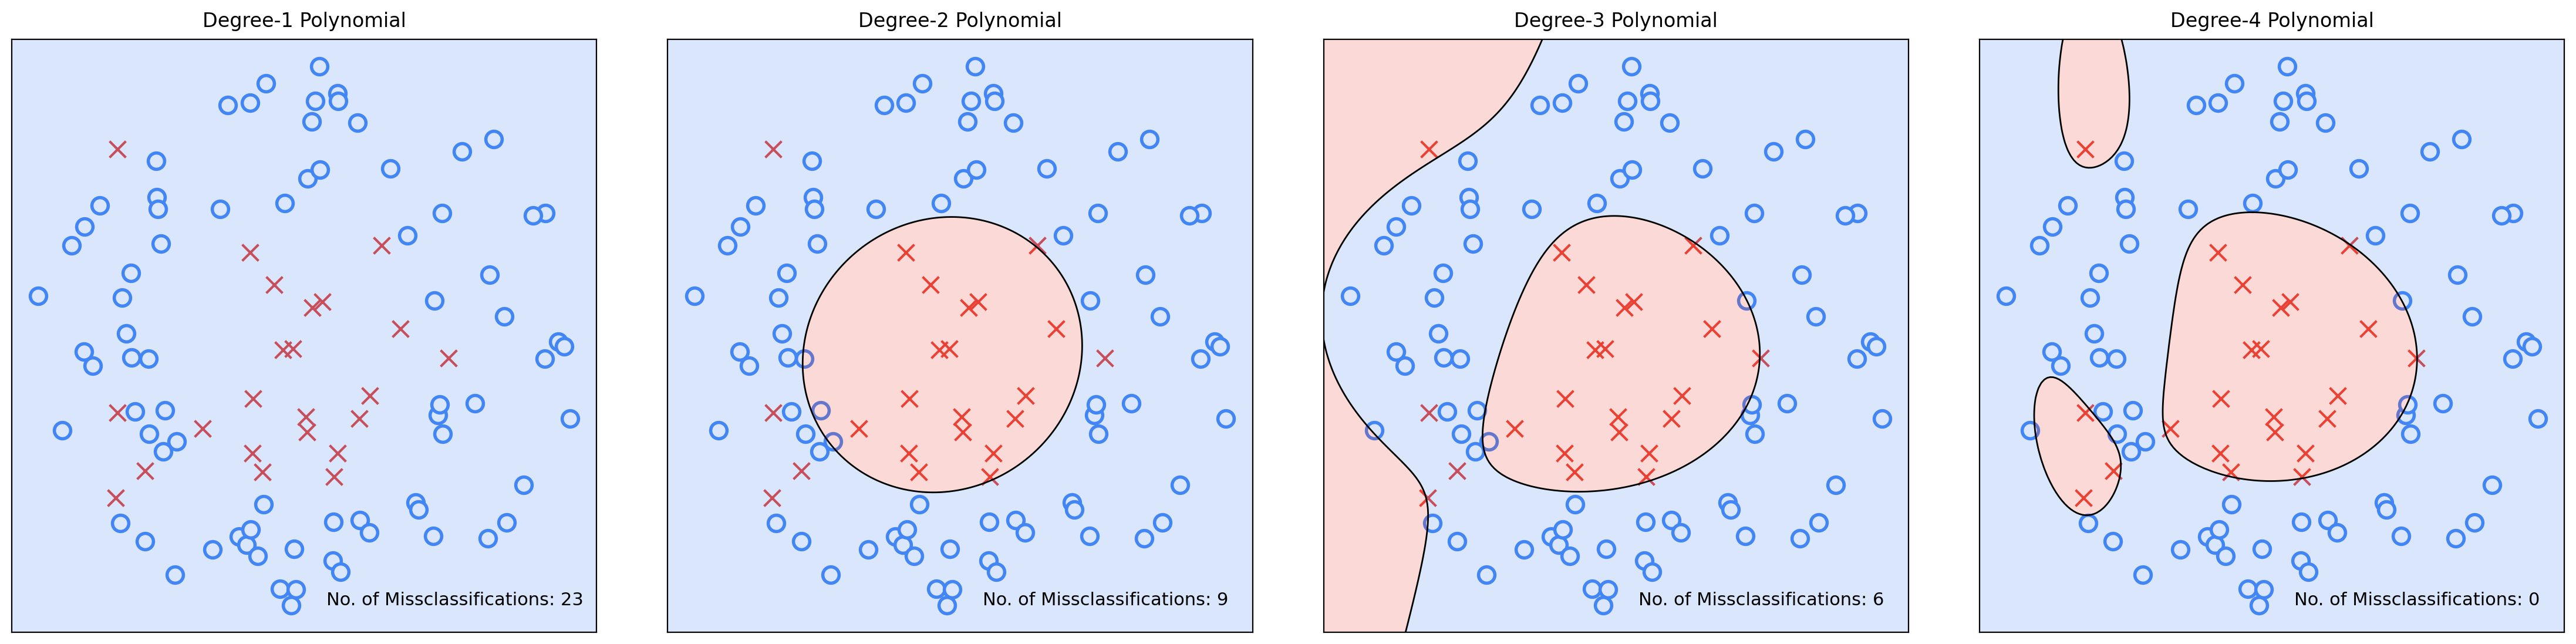

In [186]:
fig, axes = plt.subplots(1, 4, figsize=(22.4, 5.6))


for d, ax in zip(range(1, 5), axes.flat):
    ax.scatter(x_train[y_train==1, 0], x_train[y_train==1, 1], marker='x', color=(233/255, 66/255, 53/255), s=100, zorder=1)
    ax.scatter(x_train[y_train==-1, 0], x_train[y_train==-1, 1], color=(66/255, 133/255, 244/255),  s=100, marker="o", facecolor="w", lw=2)
    np.random.seed(2)

    # set the polynomial degree from 1 - 4
    pipeline_logistic.set_params(polynomial__degree=d).fit(x_train, y_train)
    xmin, xmax = ax.get_xaxis().get_view_interval()
    ymin, ymax = ax.get_yaxis().get_view_interval()

    # plot classifcation regions
    xx, yy = np.meshgrid(np.linspace(xmin, xmax, 200), np.linspace(ymin, ymax, 200))
    X_ = np.array([xx.flatten(), yy.flatten()]).T

    feat = lambda x: pipeline_logistic['polynomial'].fit_transform(x)

    zz = pipeline_logistic['classifier'].decision_function(feat(X_)).reshape(200, 200)
    cs = ax.contourf(xx, yy, zz, zz, levels=[-float("inf"), 0, float("inf")], alpha=0.2, colors=[(66/255, 133/255, 244/255), (233/255, 66/255, 53/255)])
    ax.contour(cs, colors='k', linewidths=1)
    ax.xaxis.set_visible(False)      # Hide only x axis
    ax.yaxis.set_visible(False)      # Hide only y axis
    ax.set_title(f"Degree-{d} Polynomial", fontsize=12, pad=8)
    no_misclass = (pipeline_logistic.predict(x_train) != y_train).sum()
    ax.text(0.06, -0.88, f'No. of Missclassifications: {no_misclass}', c='k', fontsize=11)

plt.tight_layout()


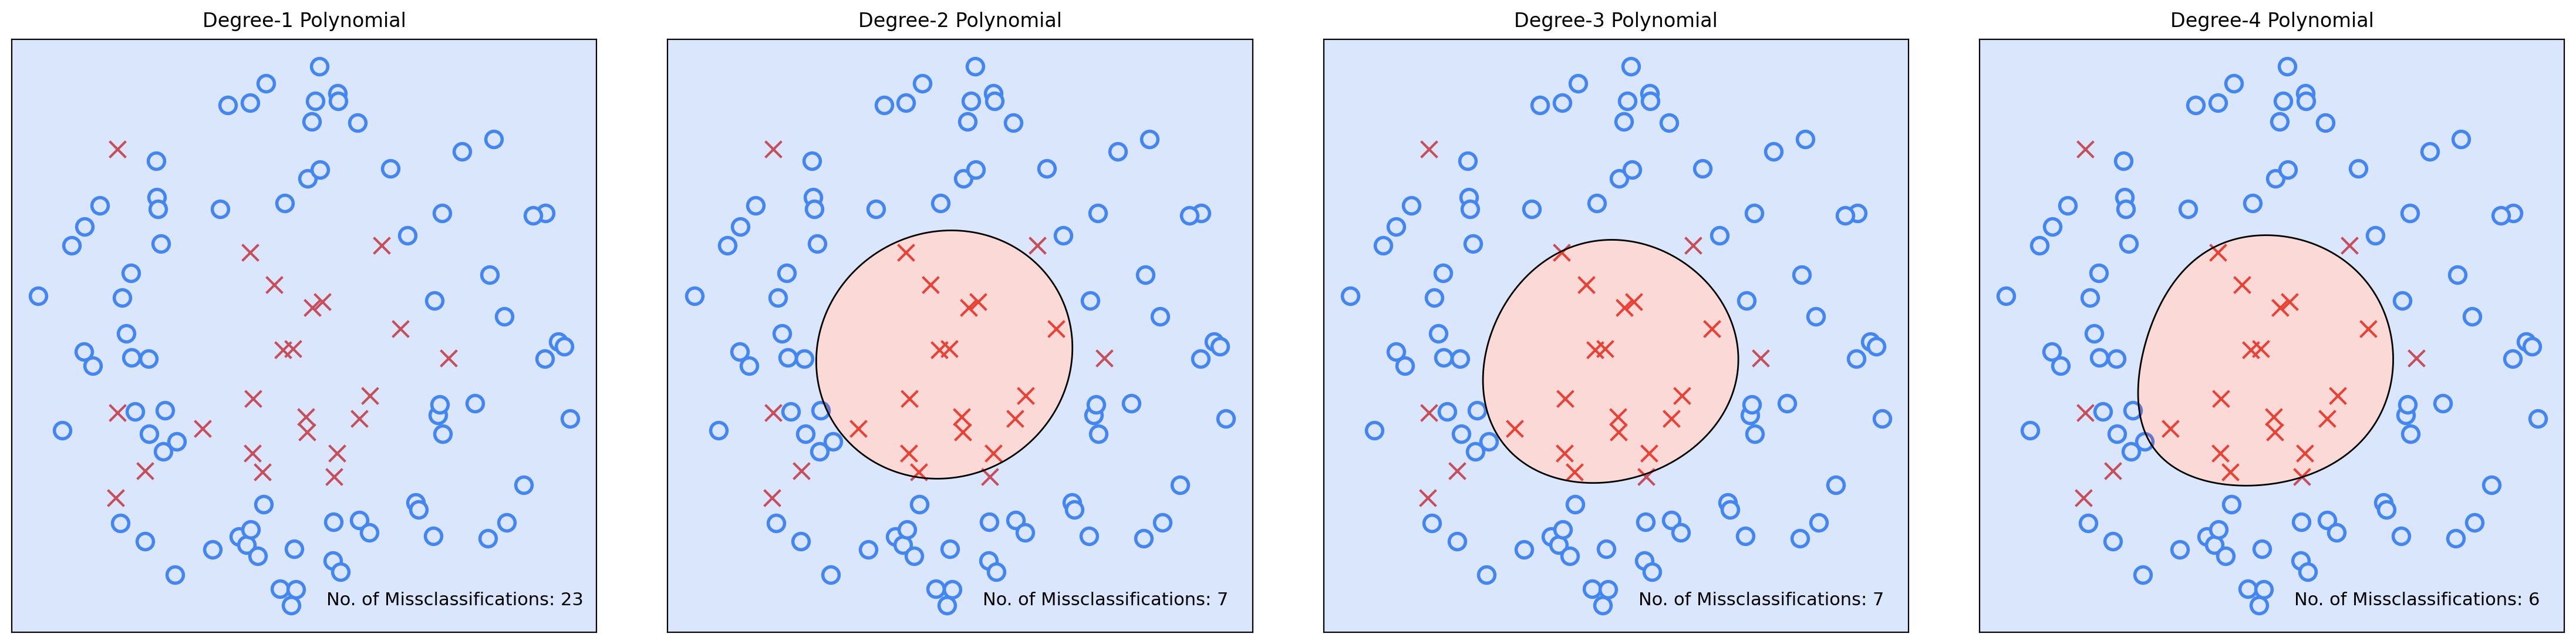

In [216]:
fig, axes = plt.subplots(1, 4, figsize=(22.4, 5.6))


for d, ax in zip(range(1, 5), axes.flat):
    ax.scatter(x_train[y_train==1, 0], x_train[y_train==1, 1], marker='x', color=(233/255, 66/255, 53/255), s=100, zorder=1)
    ax.scatter(x_train[y_train==-1, 0], x_train[y_train==-1, 1], color=(66/255, 133/255, 244/255),  s=100, marker="o", facecolor="w", lw=2)
    np.random.seed(2)

    # set the polynomial degree from 1 - 4
    pipeline_logistic.set_params(polynomial__degree=d, classifier__C=10).fit(x_train, y_train)
    xmin, xmax = ax.get_xaxis().get_view_interval()
    ymin, ymax = ax.get_yaxis().get_view_interval()

    # plot classifcation regions
    xx, yy = np.meshgrid(np.linspace(xmin, xmax, 200), np.linspace(ymin, ymax, 200))
    X_ = np.array([np.ravel(xx), np.ravel(yy)]).T

    feat = lambda x: pipeline_logistic['polynomial'].fit_transform(x)

    zz = pipeline_logistic['classifier'].decision_function(feat(X_)).reshape(200, 200)
    cs = ax.contourf(xx, yy, zz, zz, levels=[-float("inf"), 0, float("inf")], alpha=0.2, colors=[(66/255, 133/255, 244/255), (233/255, 66/255, 53/255)])
    ax.contour(cs, colors='k', linewidths=1)
    ax.xaxis.set_visible(False)      # Hide only x axis
    ax.yaxis.set_visible(False)      # Hide only x axis
    ax.set_title(f"Degree-{d} Polynomial", fontsize=12, pad=8)
    no_misclass = (pipeline_logistic.predict(x_train) != y_train).sum()
    ax.text(0.06, -0.88, f'No. of Missclassifications: {no_misclass}', c='k', fontsize=11)

plt.tight_layout()
